# Experiment Visualization - Kubernetes Mitigation Agent

**IMPORTANT:** Make sure you're using the **Python (kub-mitigation-agent)** kernel.

This notebook generates publication-quality visualizations for chaos engineering experiments with proper phase boundaries.

In [1]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from datetime import datetime
from pathlib import Path
import warnings

# Suppress font warnings
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')

# Create PLOTS directory if it doesn't exist
plots_dir = Path('PLOTS')
plots_dir.mkdir(exist_ok=True)



# Set publication-quality style
sns.set_style("whitegrid")
sns.set_context("paper", font_scale=1.5)
plt.rcParams['figure.figsize'] = (14, 10)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['DejaVu Serif', 'Liberation Serif', 'Times New Roman', 'Times']


In [ ]:
# Load experiment data
with open('DATASET_LOGS/batch_20251108_132434_app-iot-gateway/exp_001_anomaly.json', 'r') as f:
    exp_data = json.load(f)

# Extract time series data
latency_data = exp_data['prometheus_timeseries']['ingress_gateway']['latency_p95_seconds']
success_data = exp_data['prometheus_timeseries']['ingress_gateway']['success_rate_percent']

# Convert to DataFrames
df_latency = pd.DataFrame(latency_data)
df_latency['time'] = pd.to_datetime(df_latency['timestamp'], unit='s')
df_latency['seconds_elapsed'] = (df_latency['timestamp'] - df_latency['timestamp'].min())

df_success = pd.DataFrame(success_data)
df_success['time'] = pd.to_datetime(df_success['timestamp'], unit='s')
df_success['seconds_elapsed'] = (df_success['timestamp'] - df_success['timestamp'].min())

# Get experiment metadata
start_time = pd.to_datetime(exp_data['started_at'])
duration = exp_data['duration_seconds']
agent_duration = exp_data['agent_duration_seconds']
baseline_metrics = exp_data['baseline_metrics']
chaos_metrics = exp_data['chaos_metrics']
recovery_metrics = exp_data['recovery_metrics']

# Calculate actual phase boundaries from experiment config
# Based on batch_config_iot_gateway_app.yaml:
# warmup: 90s, baseline: 60s, chaos_warmup: 60s, recovery: 60s
warmup_duration = 90
baseline_duration = 60
chaos_warmup_duration = 60
recovery_duration = 60

# Phase boundaries (cumulative)
phase_warmup_end = warmup_duration
phase_baseline_end = phase_warmup_end + baseline_duration
phase_chaos_end = phase_baseline_end + chaos_warmup_duration
phase_agent_end = phase_chaos_end + agent_duration
phase_recovery_end = duration

print("✓ Data loaded successfully")
print(f"✓ Using font: {plt.rcParams['font.serif'][0]}")
print(f"\nExperiment: {exp_data['experiment_id']}")
print(f"Namespace: {exp_data['namespace']}")
print(f"Total Duration: {duration:.1f} seconds ({duration/60:.1f} minutes)")
print(f"\nPhase Boundaries:")
print(f"  Warmup:   0 - {phase_warmup_end}s")
print(f"  Baseline: {phase_warmup_end} - {phase_baseline_end}s")
print(f"  Chaos:    {phase_baseline_end} - {phase_chaos_end}s")
print(f"  Agent:    {phase_chaos_end} - {phase_agent_end:.0f}s ({agent_duration:.1f}s)")
print(f"  Recovery: {phase_agent_end:.0f} - {phase_recovery_end:.0f}s")

NameError: name 'exp_data' is not defined

In [ ]:
# Create comprehensive multi-panel figure
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Plot 1: Latency over time
ax1 = axes[0]
ax1.plot(df_latency['seconds_elapsed'], df_latency['value'], 
         linewidth=2.5, color='#2E86AB', marker='o', markersize=5, label='P95 Latency', zorder=5)

# Add baseline reference line
ax1.axhline(y=baseline_metrics['p95_latency_seconds'], 
            color='#A23B72', linestyle='--', linewidth=2, alpha=0.7, label='Baseline Reference')

# Add phase backgrounds with actual boundaries
ax1.axvspan(0, phase_warmup_end, alpha=0.08, color='gray', label='Warmup')
ax1.axvspan(phase_warmup_end, phase_baseline_end, alpha=0.12, color='green', label='Baseline')
ax1.axvspan(phase_baseline_end, phase_chaos_end, alpha=0.12, color='red', label='Chaos')
ax1.axvspan(phase_chaos_end, phase_agent_end, alpha=0.12, color='orange', label=f'Agent ({agent_duration:.0f}s)')
ax1.axvspan(phase_agent_end, phase_recovery_end, alpha=0.12, color='blue', label='Recovery')

# Add vertical lines at phase boundaries
for phase_time in [phase_warmup_end, phase_baseline_end, phase_chaos_end, phase_agent_end]:
    ax1.axvline(x=phase_time, color='black', linestyle=':', linewidth=1, alpha=0.5)

ax1.set_ylabel('P95 Latency (seconds)', fontsize=14, fontweight='bold')
ax1.set_title(f'Experiment {exp_data["experiment_id"]}: Service Metrics Over Time', 
              fontsize=16, fontweight='bold', pad=20)
ax1.legend(loc='upper right', frameon=True, shadow=True, ncol=2, fontsize=10)
ax1.grid(True, alpha=0.3)

# Plot 2: Success Rate over time
ax2 = axes[1]
ax2.plot(df_success['seconds_elapsed'], df_success['value'], 
         linewidth=2.5, color='#F18F01', marker='s', markersize=5, label='Success Rate', zorder=5)

# Add baseline reference line
ax2.axhline(y=baseline_metrics['success_rate_percent'], 
            color='#A23B72', linestyle='--', linewidth=2, alpha=0.7, label='Baseline Reference')

# Add phase backgrounds
ax2.axvspan(0, phase_warmup_end, alpha=0.08, color='gray')
ax2.axvspan(phase_warmup_end, phase_baseline_end, alpha=0.12, color='green')
ax2.axvspan(phase_baseline_end, phase_chaos_end, alpha=0.12, color='red')
ax2.axvspan(phase_chaos_end, phase_agent_end, alpha=0.12, color='orange')
ax2.axvspan(phase_agent_end, phase_recovery_end, alpha=0.12, color='blue')

# Add vertical lines at phase boundaries
for phase_time in [phase_warmup_end, phase_baseline_end, phase_chaos_end, phase_agent_end]:
    ax2.axvline(x=phase_time, color='black', linestyle=':', linewidth=1, alpha=0.5)

ax2.set_xlabel('Time Elapsed (seconds)', fontsize=14, fontweight='bold')
ax2.set_ylabel('Success Rate (%)', fontsize=14, fontweight='bold')
ax2.set_ylim([99, 100.5])
ax2.legend(loc='lower right', frameon=True, shadow=True)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('PLOTS/experiment_metrics_timeline.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Figure saved as 'PLOTS/experiment_metrics_timeline.png'")


In [ ]:
# Parse node CPU data
node_cpu_data = exp_data['prometheus_timeseries']['node_resources']['node_cpu_cores_non_idle']

# Create figure for node CPU usage
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each node's CPU usage
colors = plt.cm.tab10(np.linspace(0, 1, len(node_cpu_data)))
for idx, node_data in enumerate(node_cpu_data):
    node_name = node_data['node']
    values = [v['value'] for v in node_data['values']]
    times = np.arange(len(values)) * 15
    
    if 'edge-site-2-worker-2' in node_name:
        ax.plot(times, values, linewidth=3, label=node_name + ' (ANOMALY)', 
                color='red', marker='o', markersize=6, zorder=10)
    else:
        ax.plot(times, values, linewidth=1.5, label=node_name, 
                color=colors[idx], alpha=0.7)

# Add phase backgrounds
ax.axvspan(0, phase_warmup_end, alpha=0.08, color='gray')
ax.axvspan(phase_warmup_end, phase_baseline_end, alpha=0.12, color='green')
ax.axvspan(phase_baseline_end, phase_chaos_end, alpha=0.12, color='red')
ax.axvspan(phase_chaos_end, phase_agent_end, alpha=0.12, color='orange')
ax.axvspan(phase_agent_end, phase_recovery_end, alpha=0.12, color='blue')

for phase_time in [phase_warmup_end, phase_baseline_end, phase_chaos_end, phase_agent_end]:
    ax.axvline(x=phase_time, color='black', linestyle=':', linewidth=1, alpha=0.5)

ax.set_xlabel('Time Elapsed (seconds)', fontsize=14, fontweight='bold')
ax.set_ylabel('CPU Usage (cores)', fontsize=14, fontweight='bold')
ax.set_title('Node CPU Usage Over Time', fontsize=16, fontweight='bold', pad=20)
ax.legend(loc='upper left', frameon=True, shadow=True, ncol=2, fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('PLOTS/node_cpu_usage.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figure saved as 'PLOTS/node_cpu_usage.png'")


In [ ]:
# Parse pod CPU data per node
pod_cpu_data = exp_data['prometheus_timeseries']['node_resources']['pod_cpu_per_node']

fig, ax = plt.subplots(figsize=(16, 8))

colors = plt.cm.tab10(np.linspace(0, 1, len(pod_cpu_data)))
for idx, node_data in enumerate(pod_cpu_data):
    node_name = node_data['node']
    values = [v['value'] for v in node_data['values']]
    times = np.arange(len(values)) * 15
    
    if 'edge-site-2-worker-2' in node_name:
        ax.plot(times, values, linewidth=3, label=node_name + ' (near-zero pods)', 
                color='red', marker='o', markersize=6, zorder=10, linestyle='--')
    else:
        ax.plot(times, values, linewidth=1.5, label=node_name, color=colors[idx], alpha=0.7)

# Add phase backgrounds
ax.axvspan(0, phase_warmup_end, alpha=0.08, color='gray')
ax.axvspan(phase_warmup_end, phase_baseline_end, alpha=0.12, color='green')
ax.axvspan(phase_baseline_end, phase_chaos_end, alpha=0.12, color='red')
ax.axvspan(phase_chaos_end, phase_agent_end, alpha=0.12, color='orange')
ax.axvspan(phase_agent_end, phase_recovery_end, alpha=0.12, color='blue')

for phase_time in [phase_warmup_end, phase_baseline_end, phase_chaos_end, phase_agent_end]:
    ax.axvline(x=phase_time, color='black', linestyle=':', linewidth=1, alpha=0.5)

ax.set_xlabel('Time Elapsed (seconds)', fontsize=14, fontweight='bold')
ax.set_ylabel('Pod CPU Usage (cores)', fontsize=14, fontweight='bold')
ax.set_title('Pod CPU Usage per Node', fontsize=16, fontweight='bold', pad=20)
ax.legend(loc='upper left', frameon=True, shadow=True, ncol=2, fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('PLOTS/pod_cpu_per_node.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figure saved as 'PLOTS/pod_cpu_per_node.png'")


In [ ]:
# Create phase comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

phases = ['Baseline', 'Chaos', 'Recovery']
latencies = [
    baseline_metrics['p95_latency_seconds'],
    chaos_metrics['p95_latency_seconds'],
    recovery_metrics['p95_latency_seconds']
]
success_rates = [
    baseline_metrics['success_rate_percent'],
    chaos_metrics['success_rate_percent'],
    recovery_metrics['success_rate_percent']
]

# Latency comparison
ax1 = axes[0]
bars1 = ax1.bar(phases, latencies, color=['#06A77D', '#D62246', '#2E86AB'], 
                edgecolor='black', linewidth=1.5, alpha=0.8)
ax1.set_ylabel('P95 Latency (seconds)', fontsize=12, fontweight='bold')
ax1.set_title('Latency Comparison Across Phases', fontsize=14, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.3f}s', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Success rate comparison
ax2 = axes[1]
bars2 = ax2.bar(phases, success_rates, color=['#06A77D', '#D62246', '#2E86AB'],
                edgecolor='black', linewidth=1.5, alpha=0.8)
ax2.set_ylabel('Success Rate (%)', fontsize=12, fontweight='bold')
ax2.set_title('Success Rate Comparison', fontsize=14, fontweight='bold')
ax2.set_ylim([99, 100.5])
ax2.grid(axis='y', alpha=0.3)

for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('PLOTS/phase_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figure saved as 'PLOTS/phase_comparison.png'")


In [ ]:
# Create experiment summary
fig, ax = plt.subplots(figsize=(14, 11))
ax.axis('off')

summary_text = f"""
EXPERIMENT SUMMARY
{'='*90}

Configuration:
  • Experiment ID: {exp_data['experiment_id']}
  • Batch ID: {exp_data['batch_id']}
  • Namespace: {exp_data['namespace']}
  • Started: {exp_data['started_at']}
  • Total Duration: {duration:.1f}s ({duration/60:.2f} min)

{'='*90}

Experiment Phases:

  Phase 1 - WARMUP ({warmup_duration}s):
    Time: 0 - {phase_warmup_end}s

  Phase 2 - BASELINE ({baseline_duration}s):
    Time: {phase_warmup_end} - {phase_baseline_end}s
    • P95 Latency: {baseline_metrics['p95_latency_seconds']:.3f}s
    • Success Rate: {baseline_metrics['success_rate_percent']:.2f}%
    • Requests: {baseline_metrics['total_requests']}

  Phase 3 - CHAOS ({chaos_warmup_duration}s):
    Time: {phase_baseline_end} - {phase_chaos_end}s
    • P95 Latency: {chaos_metrics['p95_latency_seconds']:.3f}s
    • Success Rate: {chaos_metrics['success_rate_percent']:.2f}%
    • Requests: {chaos_metrics['total_requests']}
    • Type: Node CPU Stress (edge-site-2-worker-2)

  Phase 4 - AGENT EXECUTION ({agent_duration:.1f}s):
    Time: {phase_chaos_end} - {phase_agent_end:.0f}s
    • Actions: {len(exp_data.get('agent_actions', []))}
    • Duration: {agent_duration:.1f}s ({agent_duration/60:.2f} min)

  Phase 5 - RECOVERY ({recovery_duration}s):
    Time: {phase_agent_end:.0f} - {phase_recovery_end:.0f}s
    • P95 Latency: {recovery_metrics['p95_latency_seconds']:.3f}s
    • Success Rate: {recovery_metrics['success_rate_percent']:.2f}%
    • Requests: {recovery_metrics['total_requests']}

{'='*90}

Agent Performance:
  • Status: {exp_data['operational_summary']['status']}
  • Success: {exp_data['agent_success']}
  • Recovery: {exp_data['recovery_successful']}
  • Reason: {exp_data['recovery_reason']}

Problem Detection:
  • Expected: {exp_data['location_evaluation']['expected_target']}
  • Identified: {exp_data['location_evaluation']['location_identified']}
"""

ax.text(0.05, 0.98, summary_text, transform=ax.transAxes,
        fontsize=10, verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.savefig('PLOTS/experiment_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figure saved as 'PLOTS/experiment_summary.png'")


In [ ]:
# Extract time series data
latency_data = exp_data['prometheus_timeseries']['ingress_gateway']['latency_p95_seconds']
success_data = exp_data['prometheus_timeseries']['ingress_gateway']['success_rate_percent']

# Convert to DataFrames
df_latency = pd.DataFrame(latency_data)
df_latency['time'] = pd.to_datetime(df_latency['timestamp'], unit='s')
df_latency['seconds_elapsed'] = (df_latency['timestamp'] - df_latency['timestamp'].min())

df_success = pd.DataFrame(success_data)
df_success['time'] = pd.to_datetime(df_success['timestamp'], unit='s')
df_success['seconds_elapsed'] = (df_success['timestamp'] - df_success['timestamp'].min())

# Get experiment metadata
start_time = pd.to_datetime(exp_data['started_at'])
duration = exp_data['duration_seconds']
agent_duration = exp_data['agent_duration_seconds']
baseline_metrics = exp_data['baseline_metrics']
chaos_metrics = exp_data['chaos_metrics']
recovery_metrics = exp_data['recovery_metrics']

# Calculate actual phase boundaries from experiment config
# Based on batch_config_iot_gateway_app.yaml:
# warmup: 90s, baseline: 60s, chaos_warmup: 60s, recovery: 60s
warmup_duration = 90
baseline_duration = 60
chaos_warmup_duration = 60
recovery_duration = 60

# Phase boundaries (cumulative)
phase_warmup_end = warmup_duration
phase_baseline_end = phase_warmup_end + baseline_duration
phase_chaos_end = phase_baseline_end + chaos_warmup_duration
phase_agent_end = phase_chaos_end + agent_duration
phase_recovery_end = duration

print(f"Experiment: {exp_data['experiment_id']}")
print(f"Namespace: {exp_data['namespace']}")
print(f"Total Duration: {duration:.1f} seconds ({duration/60:.1f} minutes)")
print(f"\nPhase Boundaries:")
print(f"  Warmup:   0 - {phase_warmup_end}s")
print(f"  Baseline: {phase_warmup_end} - {phase_baseline_end}s")
print(f"  Chaos:    {phase_baseline_end} - {phase_chaos_end}s")
print(f"  Agent:    {phase_chaos_end} - {phase_agent_end:.0f}s ({agent_duration:.1f}s)")
print(f"  Recovery: {phase_agent_end:.0f} - {phase_recovery_end:.0f}s")
print(f"\nMetrics Summary:")
print(f"  Baseline: p95={baseline_metrics['p95_latency_seconds']}s, success={baseline_metrics['success_rate_percent']}%")
print(f"  Chaos:    p95={chaos_metrics['p95_latency_seconds']}s, success={chaos_metrics['success_rate_percent']}%")
print(f"  Recovery: p95={recovery_metrics['p95_latency_seconds']}s, success={recovery_metrics['success_rate_percent']}%")

In [6]:
# Analyze baseline vs chaos latency across the latest batch
from IPython.display import display

batch_path = Path('DATASET_LOGS/batch_20251110_141027_app-iot-gateway')
if not batch_path.exists():
    raise FileNotFoundError(f'Batch path not found: {batch_path}')

records = []
for json_path in sorted(batch_path.glob('exp_*.json')):
    with json_path.open() as f:
        data = json.load(f)

    chaos_config = data.get('chaos_config') or {}
    parameters = chaos_config.get('parameters') or {}
    provider = chaos_config.get('provider') or 'unknown'
    anomaly_type = chaos_config.get('fault_type') or chaos_config.get('type') or 'unspecified'
    scope = 'node' if provider == 'chaosd' else ('pod' if provider == 'chaosmesh' else provider)
    scenario_label = chaos_config.get('name') or f"{anomaly_type} ({scope})"
    target_info = chaos_config.get('target') or {}
    target_label = next((target_info.get(key) for key in ('name', 'app', 'node', 'namespace', 'resource') if target_info.get(key)), None)

    baseline_metrics = data.get('baseline_metrics') or {}
    chaos_metrics = data.get('chaos_metrics') or {}
    baseline_latency = float(baseline_metrics.get('p95_latency_seconds', 0.0) or 0.0)
    chaos_latency = float(chaos_metrics.get('p95_latency_seconds', 0.0) or 0.0)
    baseline_success = float(baseline_metrics.get('success_rate_percent', 0.0) or 0.0)
    chaos_success = float(chaos_metrics.get('success_rate_percent', 0.0) or 0.0)

    delta_latency = chaos_latency - baseline_latency
    percent_change_latency = (delta_latency / baseline_latency * 100) if baseline_latency else np.nan
    delta_success = chaos_success - baseline_success
    percent_change_success = (delta_success / baseline_success * 100) if baseline_success else np.nan

    records.append({
        'experiment_id': data.get('experiment_id'),
        'anomaly_type': anomaly_type,
        'scenario': scenario_label,
        'provider': provider,
        'scope': scope,
        'target': target_label or 'n/a',
        'parameters': ", ".join(f"{k}={v}" for k, v in parameters.items()) or 'n/a',
        'baseline_p95_latency_s': baseline_latency,
        'chaos_p95_latency_s': chaos_latency,
        'delta_latency_s': delta_latency,
        'percent_change_latency': percent_change_latency,
        'baseline_success_rate_percent': baseline_success,
        'chaos_success_rate_percent': chaos_success,
        'success_delta_pct_pts': delta_success,
        'success_percent_change': percent_change_success,
    })

if not records:
    raise ValueError(f'No experiment files found under {batch_path}')

latency_df = pd.DataFrame(records)
latency_df = latency_df.sort_values(['anomaly_type', 'experiment_id']).reset_index(drop=True)

rounded_latency_df = latency_df.copy()
for col in ['baseline_p95_latency_s', 'chaos_p95_latency_s', 'delta_latency_s']:
    rounded_latency_df[col] = rounded_latency_df[col].round(3)
for col in ['baseline_success_rate_percent', 'chaos_success_rate_percent', 'success_delta_pct_pts']:
    rounded_latency_df[col] = rounded_latency_df[col].round(2)
rounded_latency_df['percent_change_latency'] = rounded_latency_df['percent_change_latency'].round(1)
rounded_latency_df['success_percent_change'] = rounded_latency_df['success_percent_change'].round(1)

print('Per-experiment baseline vs chaos latency & success metrics')
display(rounded_latency_df)

latency_by_type = (
    latency_df
    .groupby('anomaly_type', as_index=False)
    .agg(
        experiments=('experiment_id', 'count'),
        baseline_mean_latency_s=('baseline_p95_latency_s', 'mean'),
        chaos_mean_latency_s=('chaos_p95_latency_s', 'mean'),
        latency_delta_mean_s=('delta_latency_s', 'mean'),
        baseline_median_latency_s=('baseline_p95_latency_s', 'median'),
        chaos_median_latency_s=('chaos_p95_latency_s', 'median'),
        baseline_mean_success_percent=('baseline_success_rate_percent', 'mean'),
        chaos_mean_success_percent=('chaos_success_rate_percent', 'mean'),
        success_delta_mean_pct_pts=('success_delta_pct_pts', 'mean'),
        success_percent_change_mean=('success_percent_change', 'mean'),
    )
    .sort_values('anomaly_type')
)

latency_by_type[['baseline_mean_latency_s', 'chaos_mean_latency_s', 'latency_delta_mean_s',
                 'baseline_median_latency_s', 'chaos_median_latency_s']] = (
    latency_by_type[['baseline_mean_latency_s', 'chaos_mean_latency_s', 'latency_delta_mean_s',
                     'baseline_median_latency_s', 'chaos_median_latency_s']].round(3)
)
latency_by_type[['baseline_mean_success_percent', 'chaos_mean_success_percent',
                 'success_delta_mean_pct_pts']] = (
    latency_by_type[['baseline_mean_success_percent', 'chaos_mean_success_percent',
                     'success_delta_mean_pct_pts']].round(2)
)
latency_by_type['success_percent_change_mean'] = latency_by_type['success_percent_change_mean'].round(1)

print('\nLatency & success summary by anomaly type')
display(latency_by_type)

# Keep reference for downstream plotting
grouped_latency = latency_by_type.copy()



Per-experiment baseline vs chaos latency & success metrics


,experiment_id,anomaly_type,scenario,provider,scope,target,parameters,baseline_p95_latency_s,chaos_p95_latency_s,delta_latency_s,percent_change_latency,baseline_success_rate_percent,chaos_success_rate_percent,success_delta_pct_pts,success_percent_change
0,exp_001-chaos-cpu-stress-iot-gateway-edge-site-1,cpu_stress,cpu-one-gateway-site-1,chaosmesh,pod,iot-gateway-edge-site-1,"workers=2, load=85",0.185,0.176,-0.009,-4.9,100.00,99.79,-0.21,-0.2
1,exp_002-chaos-cpu-stress-edge-data-processor-e...,cpu_stress,cpu-one-edge-processor,chaosmesh,pod,edge-data-processor-edge-site-1,"workers=3, load=95",0.179,0.408,0.229,127.9,99.93,100.00,0.07,0.1
2,exp_003-chaos-cpu-stress-iot-gateway-edge-site-2,cpu_stress,cpu-all-gateway-site-2,chaosmesh,pod,iot-gateway-edge-site-2,"workers=2, load=88",0.163,0.181,0.018,11.0,100.00,100.00,0.00,0.0
3,exp_004-chaos-cpu-stress-cloud-analytics-engin...,cpu_stress,cpu-all-cloud-analytics,chaosmesh,pod,cloud-analytics-engine-cloud,"workers=4, load=92",0.178,0.783,0.605,339.9,100.00,99.91,-0.09,-0.1
4,exp_005-chaos-memory-stress-iot-gateway-edge-s...,memory_stress,memory-one-gateway-site-1,chaosmesh,pod,iot-gateway-edge-site-1,"size=1GB, workers=1",0.176,0.182,0.006,3.4,100.00,99.93,-0.07,-0.1
5,exp_006-chaos-memory-stress-edge-data-processo...,memory_stress,memory-one-edge-processor,chaosmesh,pod,edge-data-processor-edge-site-1,"size=2GB, workers=2",0.173,0.167,-0.006,-3.5,100.00,100.00,0.00,0.0
6,exp_007-chaos-memory-stress-iot-gateway-edge-s...,memory_stress,memory-all-gateway-site-2,chaosmesh,pod,iot-gateway-edge-site-2,"size=2GB, workers=2",0.169,0.187,0.018,10.7,100.00,100.00,0.00,0.0
7,exp_008-chaos-memory-stress-cloud-analytics-en...,memory_stress,memory-all-cloud-analytics,chaosmesh,pod,cloud-analytics-engine-cloud,"size=2.5GB, workers=3",0.181,0.178,-0.003,-1.7,100.00,99.93,-0.07,-0.1
8,exp_013-chaos-node-cpu-stress-cloud-worker-1,node_cpu_stress,node-cpu-cloud-1,chaosd,node,cloud-worker-1,"load=90, workers=6",0.167,0.478,0.311,186.2,100.00,100.00,0.00,0.0
9,exp_014-chaos-node-cpu-stress-edge-site-1-work...,node_cpu_stress,node-cpu-edge-1,chaosd,node,edge-site-1-worker-1,"load=88, workers=5",0.190,0.455,0.265,139.5,100.00,100.00,0.00,0.0



Latency & success summary by anomaly type


,anomaly_type,experiments,baseline_mean_latency_s,chaos_mean_latency_s,latency_delta_mean_s,baseline_median_latency_s,chaos_median_latency_s,baseline_mean_success_percent,chaos_mean_success_percent,success_delta_mean_pct_pts,success_percent_change_mean
0,cpu_stress,4,0.176,0.387,0.211,0.178,0.294,99.98,99.92,-0.06,-0.1
1,memory_stress,4,0.175,0.178,0.004,0.174,0.180,100.00,99.96,-0.03,-0.0
2,node_cpu_stress,3,0.176,0.391,0.215,0.171,0.455,100.00,100.00,0.00,0.0
3,node_mem_stress,3,0.175,0.253,0.078,0.178,0.242,100.00,99.98,-0.02,-0.0
4,pod_failure,4,0.183,0.175,-0.008,0.186,0.182,100.00,75.00,-25.00,-25.0


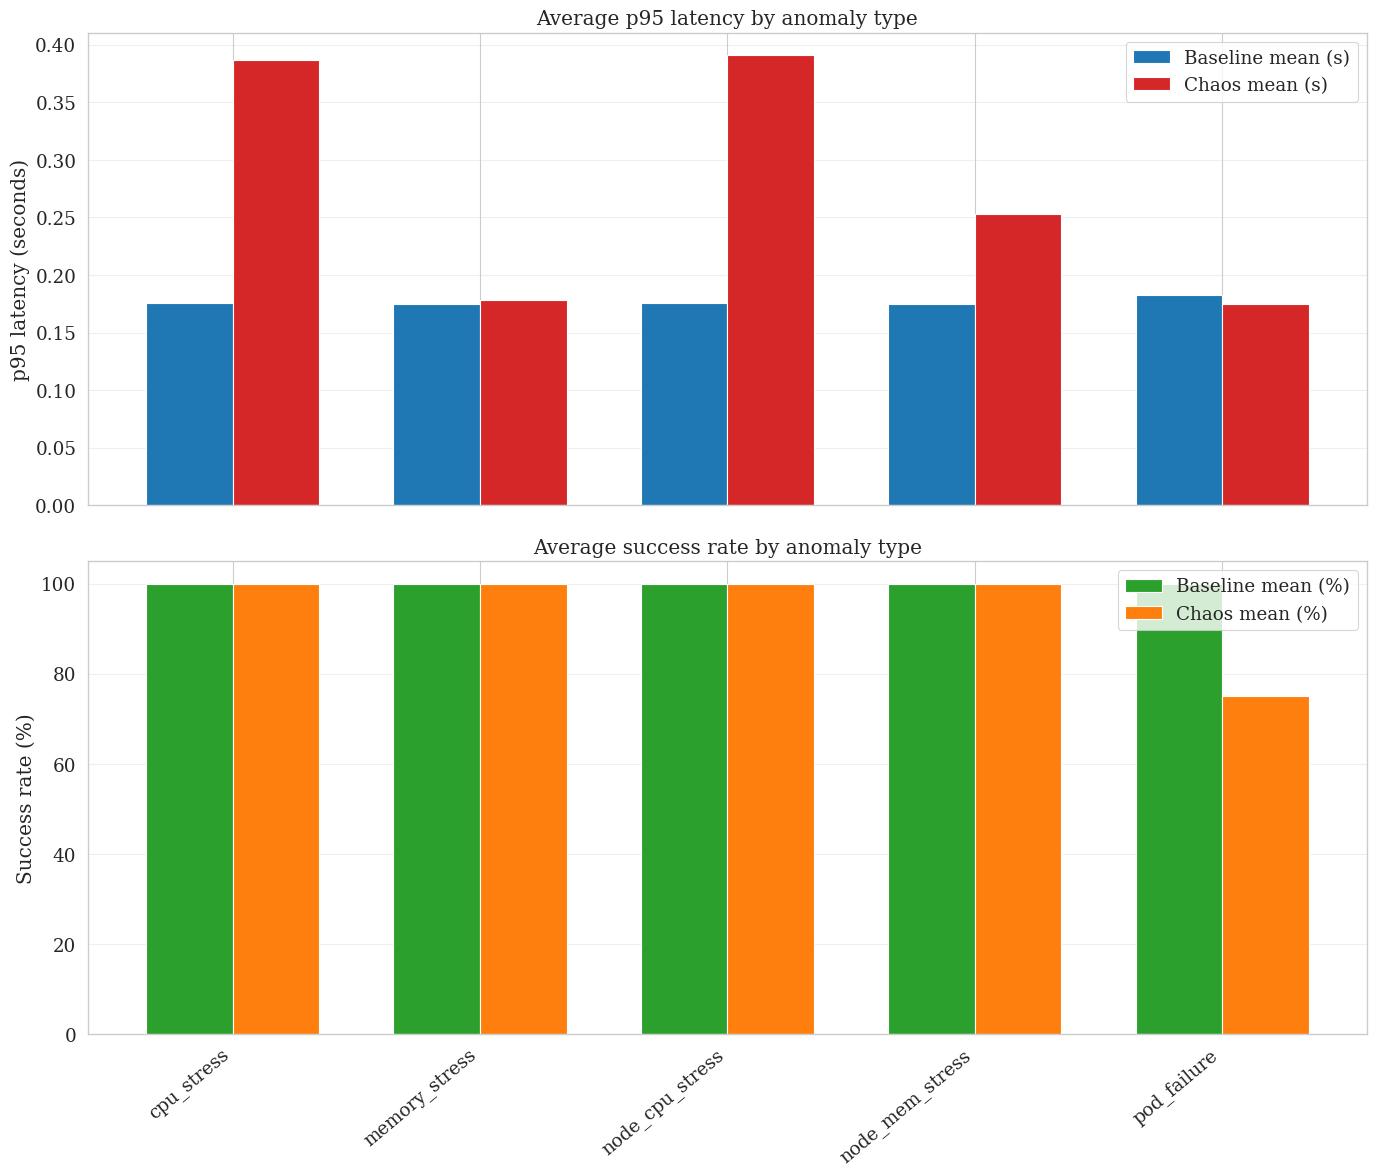

✓ Figure saved as 'PLOTS/latency_success_by_anomaly_type.png'


In [7]:
# Visualize average baseline vs chaos latency and success by anomaly type
if 'latency_by_type' not in globals():
    raise RuntimeError('Run the previous cell to build latency_by_type before plotting averages.')

plot_df = latency_by_type.set_index('anomaly_type')
anomaly_types = plot_df.index.tolist()
x = np.arange(len(anomaly_types))
width = 0.35

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), sharex=True)

ax1.bar(x - width / 2, plot_df['baseline_mean_latency_s'], width, label='Baseline mean (s)', color='#1f77b4')
ax1.bar(x + width / 2, plot_df['chaos_mean_latency_s'], width, label='Chaos mean (s)', color='#d62728')
ax1.set_ylabel('p95 latency (seconds)')
ax1.set_title('Average p95 latency by anomaly type')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

ax2.bar(x - width / 2, plot_df['baseline_mean_success_percent'], width, label='Baseline mean (%)', color='#2ca02c')
ax2.bar(x + width / 2, plot_df['chaos_mean_success_percent'], width, label='Chaos mean (%)', color='#ff7f0e')
ax2.set_ylabel('Success rate (%)')
ax2.set_title('Average success rate by anomaly type')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

ax2.set_xticks(x)
ax2.set_xticklabels(anomaly_types, rotation=40, ha='right')

plt.tight_layout()
plt.savefig('PLOTS/latency_success_by_anomaly_type.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Figure saved as 'PLOTS/latency_success_by_anomaly_type.png'")

